# Particle in a One-Dimensional Infinite Potential Well
## Project 01 — Quantum Bound States

### Objective
Compare the analytical solution of the time-independent Schrödinger equation with a numerical finite-difference solution.

### Physical model
$$
V(x)=\begin{cases}
0, & 0<x<L,\\
\infty, & \text{otherwise}.
\end{cases}
$$
The boundary conditions are $\psi(0)=\psi(L)=0$. We consider an electron in a box of length $L=1\,\mathrm{nm}$.

### Investigation
1. Calculate analytical energy eigenvalues.
2. Construct the finite-difference Hamiltonian.
3. Calculate numerical eigenvalues and eigenvectors.
4. Compare energies and visualise wavefunctions and probability densities.
5. Investigate convergence as the grid is refined.


## 1. Analytical solution
Inside the well, $V(x)=0$, so the time-independent Schrödinger equation is
$$-\frac{\hbar^2}{2m}\frac{d^2\psi}{dx^2}=E\psi.$$

The normalised eigenfunctions and energy eigenvalues are
$$\psi_n(x)=\sqrt{\frac{2}{L}}\sin\left(\frac{n\pi x}{L}\right),$$
$$E_n=\frac{n^2\pi^2\hbar^2}{2mL^2},\qquad n=1,2,3,\ldots$$

Energy is quantised and increases as $n^2$. The probability density is $|\psi_n(x)|^2$.


## 2. Constants and parameters
We use SI units for calculations and convert energies to electronvolts (eV).

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal

hbar = 1.054571817e-34       # Reduced Planck constant (J s)
mass = 9.1093837139e-31      # Electron mass (kg)
eV = 1.602176634e-19         # One electronvolt (J)
L = 1.0e-9                   # Box length (m)
N = 200                      # Number of grid intervals
number_of_states = 5

x = np.linspace(0, L, N + 1)
h = L / N
M = N - 1                    # Interior grid points

print(f"Box length: {L:.3e} m")
print(f"Grid intervals: {N}")
print(f"Interior grid points: {M}")
print(f"Grid spacing: {h:.3e} m")

Box length: 1.000e-09 m
Grid intervals: 200
Interior grid points: 199
Grid spacing: 5.000e-12 m


## 3. Analytical energy eigenvalues
For each quantum number, calculate $E_n=n^2\pi^2\hbar^2/(2mL^2)$.

In [20]:
n = np.arange(1, number_of_states + 1)
E_exact = n**2 * np.pi**2 * hbar**2 / (2 * mass * L**2)
E_exact_eV = E_exact / eV

print("Analytical energy levels")
for quantum_number, energy in zip(n, E_exact_eV):
    print(f"n = {quantum_number}: E = {energy:.8f} eV")

Analytical energy levels
n = 1: E = 0.37603016 eV
n = 2: E = 1.50412065 eV
n = 3: E = 3.38427145 eV
n = 4: E = 6.01648259 eV
n = 5: E = 9.40075404 eV


## 4. Numerical solution: finite-difference Hamiltonian
Using the central difference approximation,
$$\frac{d^2\psi}{dx^2}\bigg|_{x_i}\approx\frac{\psi_{i+1}-2\psi_i+\psi_{i-1}}{h^2},$$
the Hamiltonian is tridiagonal. Its diagonal elements are $2C$, adjacent off-diagonal elements are $-C$, where $C=\hbar^2/(2mh^2)$. With zero boundary values, there are $N-1$ interior points.

In [21]:
C = hbar**2 / (2 * mass * h**2)
diagonal = np.full(M, 2 * C)
off_diagonal = np.full(M - 1, -C)

energy_num, eigenvectors = eigh_tridiagonal(
    diagonal, off_diagonal,
    select="i", select_range=(0, number_of_states - 1)
)
E_num_eV = energy_num / eV
print(f"Calculated {len(E_num_eV)} states using a {M} x {M} Hamiltonian.")

Calculated 5 states using a 199 x 199 Hamiltonian.


## 5. Energy comparison
Absolute error is $|E_{\mathrm{num}}-E_{\mathrm{exact}}|$. Percentage error is the absolute error divided by the analytical energy, multiplied by 100.

n    Analytical (eV)     Numerical (eV)      Error (%)     
-----------------------------------------------------------
1    0.37603016          0.37602243          0.002056      
2    1.50412065          1.50399694          0.008224      
3    3.38427145          3.38364522          0.018504      
4    6.01648259          6.01450350          0.032894      
5    9.40075404          9.39592265          0.051394      


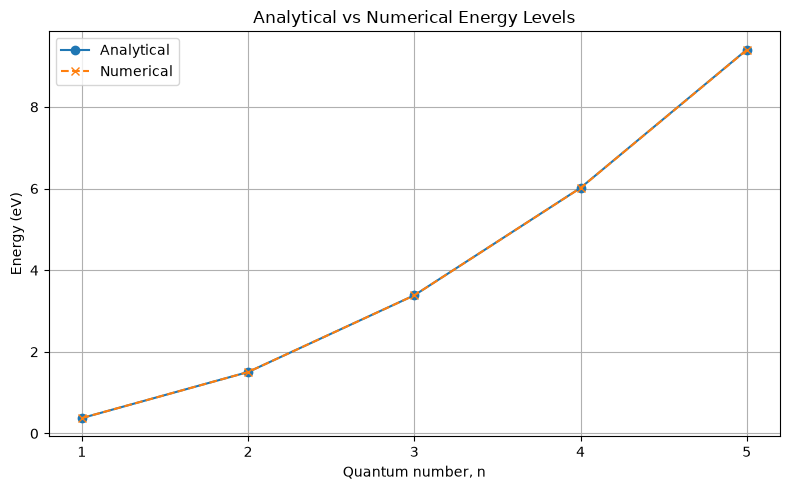

In [22]:
absolute_error_eV = np.abs(E_num_eV - E_exact_eV)
percentage_error = absolute_error_eV / E_exact_eV * 100

print(f"{'n':<5}{'Analytical (eV)':<20}{'Numerical (eV)':<20}{'Error (%)':<14}")
print("-" * 59)
for i in range(number_of_states):
    print(f"{n[i]:<5}{E_exact_eV[i]:<20.8f}{E_num_eV[i]:<20.8f}{percentage_error[i]:<14.6f}")

plt.figure(figsize=(8, 5))
plt.plot(n, E_exact_eV, "o-", label="Analytical")
plt.plot(n, E_num_eV, "x--", label="Numerical")
plt.xlabel("Quantum number, n")
plt.ylabel("Energy (eV)")
plt.title("Analytical vs Numerical Energy Levels")
plt.xticks(n)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Wavefunctions
The numerical eigenvectors are normalised in the discrete Euclidean norm. Dividing by $\sqrt{h}$ approximates continuum normalisation. We add zero-valued boundary points. Since an eigenvector's overall sign is arbitrary, signs are aligned with the analytical wavefunctions for plotting.

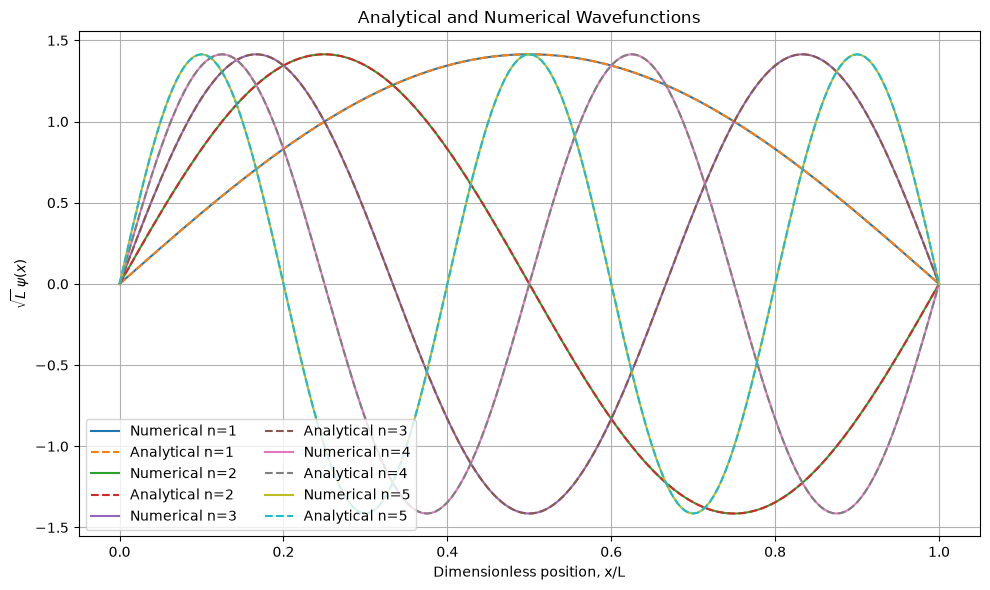

In [23]:
psi_num = eigenvectors / np.sqrt(h)
psi_num_full = np.zeros((N + 1, number_of_states))
psi_num_full[1:-1, :] = psi_num

psi_exact = np.zeros((N + 1, number_of_states))
for j, quantum_number in enumerate(n):
    psi_exact[:, j] = np.sqrt(2 / L) * np.sin(quantum_number * np.pi * x / L)

for j in range(number_of_states):
    overlap = np.trapezoid(psi_num_full[:, j] * psi_exact[:, j], x)
    if overlap < 0:
        psi_num_full[:, j] *= -1

plt.figure(figsize=(10, 6))
for j in range(number_of_states):
    plt.plot(x / L, np.sqrt(L) * psi_num_full[:, j], label=f"Numerical n={j+1}")
    plt.plot(x / L, np.sqrt(L) * psi_exact[:, j], "--", label=f"Analytical n={j+1}")
plt.xlabel("Dimensionless position, x/L")
plt.ylabel(r"$\sqrt{L}\,\psi(x)$")
plt.title("Analytical and Numerical Wavefunctions")
plt.grid(True)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## 7. Probability densities
The probability density is $|\psi_n(x)|^2$, and the probability of finding the particle between $a$ and $b$ is
$$P(a\\leq x\\leq b)=\\int_a^b |\\psi_n(x)|^2\\,dx.$$
We plot the dimensionless density $L|\\psi(x)|^2$ against $x/L$.

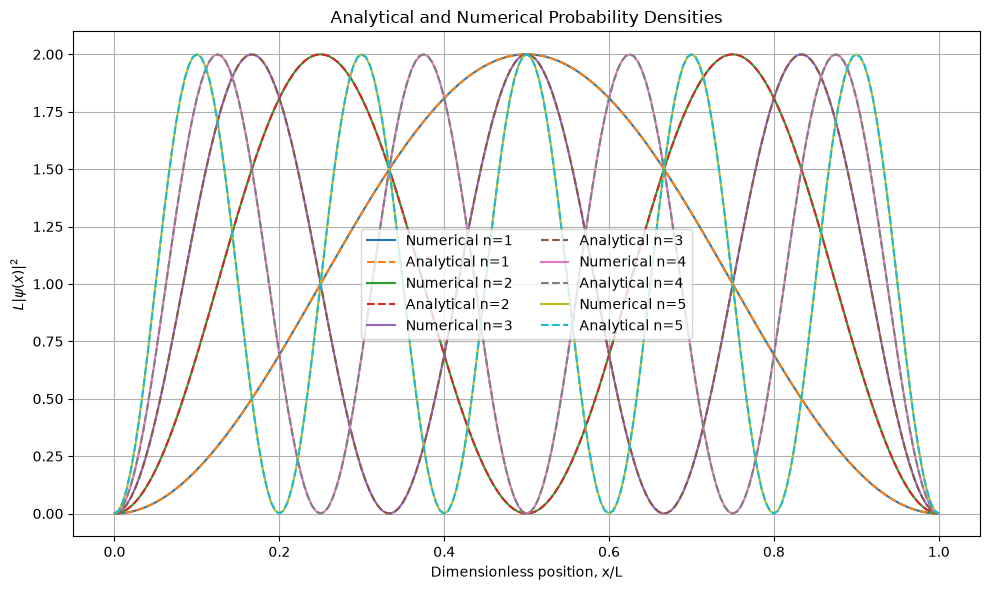

In [24]:
plt.figure(figsize=(10, 6))
for j in range(number_of_states):
    plt.plot(x / L, L * np.abs(psi_num_full[:, j])**2, label=f"Numerical n={j+1}")
    plt.plot(x / L, L * np.abs(psi_exact[:, j])**2, "--", label=f"Analytical n={j+1}")
plt.xlabel("Dimensionless position, x/L")
plt.ylabel(r"$L|\psi(x)|^2$")
plt.title("Analytical and Numerical Probability Densities")
plt.grid(True)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## 8. Numerical convergence
We refine the grid and track the ground-state energy. For this central finite-difference approximation, the leading energy error is expected to decrease approximately as $1/N^2$.

Intervals   Ground energy (eV)    Error (%)      
20          0.3752576163          2.05447720e-01 
50          0.3759064690          3.28943523e-02 
100         0.3759992354          8.22439975e-03 
200         0.3760224299          2.05615070e-03 
500         0.3760289246          3.28986598e-04 
1000        0.3760298524          8.22466358e-05 


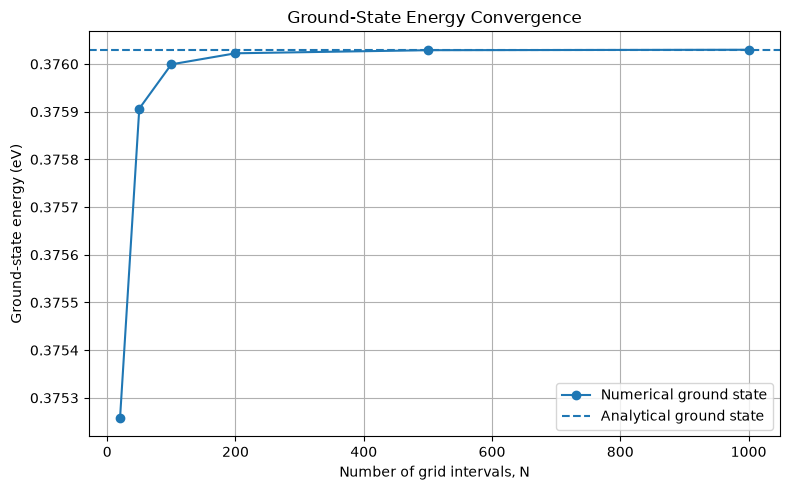

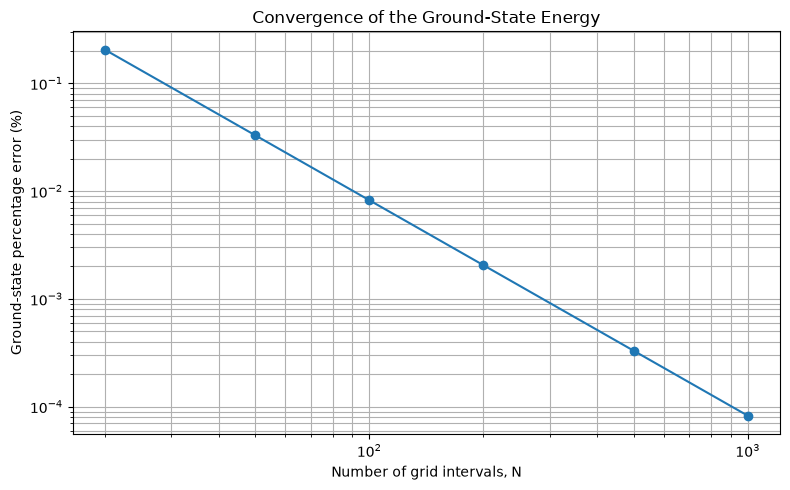

In [25]:
grid_sizes = np.array([20, 50, 100, 200, 500, 1000])
ground_energies_eV = []
ground_errors_percent = []

for grid_N in grid_sizes:
    grid_h = L / grid_N
    grid_M = grid_N - 1
    grid_C = hbar**2 / (2 * mass * grid_h**2)
    grid_diagonal = np.full(grid_M, 2 * grid_C)
    grid_off_diagonal = np.full(grid_M - 1, -grid_C)
    ground_energy = eigh_tridiagonal(
        grid_diagonal, grid_off_diagonal, eigvals_only=True,
        select="i", select_range=(0, 0)
    )[0]
    ground_energies_eV.append(ground_energy / eV)
    ground_errors_percent.append(abs(ground_energy - E_exact[0]) / E_exact[0] * 100)

ground_energies_eV = np.asarray(ground_energies_eV)
ground_errors_percent = np.asarray(ground_errors_percent)

print(f"{'Intervals':<12}{'Ground energy (eV)':<22}{'Error (%)':<15}")
for grid_N, energy, error in zip(grid_sizes, ground_energies_eV, ground_errors_percent):
    print(f"{grid_N:<12}{energy:<22.10f}{error:<15.8e}")

plt.figure(figsize=(8, 5))
plt.plot(grid_sizes, ground_energies_eV, "o-", label="Numerical ground state")
plt.axhline(E_exact_eV[0], linestyle="--", label="Analytical ground state")
plt.xlabel("Number of grid intervals, N")
plt.ylabel("Ground-state energy (eV)")
plt.title("Ground-State Energy Convergence")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.loglog(grid_sizes, ground_errors_percent, "o-")
plt.xlabel("Number of grid intervals, N")
plt.ylabel("Ground-state percentage error (%)")
plt.title("Convergence of the Ground-State Energy")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

## 9. Conclusions
Use the results to verify that:
- The analytical energy levels follow $E_n=n^2E_1$.
- Numerical energy levels approach the analytical values as the grid is refined.
- The wavefunctions vanish at the boundaries.
- Probability densities are non-negative.
- The finite-difference method's accuracy depends on grid resolution.

The notebook complements the reusable scripts in `src/` by providing an interactive, explanatory investigation.